# Patient Health Monitoring System — Exploratory Data Analysis
**HCLTech Career Shaper Programme · Project 4 · Embedded IoT**

**Goal:** understand the vitals dataset (heart rate, body temperature, SpO2) streamed by the ESP32 + MAX30100 wearable, clean it, and derive the alert thresholds that the firmware will use.

**Ethics note:** `patient_id` values are salted hashes (anonymised). The data is synthetic, so no real patient biometrics are stored.

## 1. Setup and load

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 120)

df = pd.read_csv("/kaggle/input/datasets/himanshu932/project/patient_vitals_5000.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 7)


,timestamp,patient_id,heart_rate_bpm,body_temp_C,SpO2_pct,comm_channel,alert_flag
0,2026-01-01 00:00:00,PT-7197CD24,74,36.9,97,WiFi,0
1,2026-01-01 00:00:30,PT-781530E6,82,36.7,97,LoRa,0
2,2026-01-01 00:01:00,PT-134B7920,84,36.7,97,BLE,0
3,2026-01-01 00:01:30,PT-781530E6,81,36.7,97,BLE,0
4,2026-01-01 00:02:00,PT-0FC5A992,62,36.8,96,BLE,0


## 2. Structure and data quality

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp       5000 non-null   object 
 1   patient_id      5000 non-null   object 
 2   heart_rate_bpm  5000 non-null   int64  
 3   body_temp_C     5000 non-null   float64
 4   SpO2_pct        5000 non-null   int64  
 5   comm_channel    5000 non-null   object 
 6   alert_flag      5000 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 273.6+ KB


In [6]:
print( df.isna().sum())
print(df.duplicated().sum())

timestamp         0
patient_id        0
heart_rate_bpm    0
body_temp_C       0
SpO2_pct          0
comm_channel      0
alert_flag        0
dtype: int64
0


****Cleaning and validation****

In [7]:

# Convert timestamp
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Remove duplicates and sort data
df = df.drop_duplicates()
df = df.sort_values("timestamp").reset_index(drop=True)

# Convert communication channel to category
df["comm_channel"] = df["comm_channel"].astype("category")

# Remove invalid values
df = df[
    df["heart_rate_bpm"].between(30, 220) &
    df["body_temp_C"].between(30, 43) &
    df["SpO2_pct"].between(70, 100)
]

# Check final dataset
print("Rows after cleaning:", len(df))
print("Timestamps increasing:", df["timestamp"].is_monotonic_increasing)

# Save cleaned dataset
df.to_csv("dataset_clean.csv", index=False)

Rows after cleaning: 5000
Timestamps increasing: True


## 3. Descriptive statistics

In [8]:
print(df["heart_rate_bpm"].describe())
print(df["body_temp_C"].describe())
print(df["SpO2_pct"].describe())

count    5000.000000
mean       76.770600
std        10.005218
min        41.000000
25%        71.000000
50%        77.000000
75%        82.000000
max       150.000000
Name: heart_rate_bpm, dtype: float64
count    5000.000000
mean       36.702960
std         0.254661
min        34.800000
25%        36.600000
50%        36.700000
75%        36.800000
max        39.800000
Name: body_temp_C, dtype: float64
count    5000.000000
mean       97.230800
std         1.264378
min        86.000000
25%        97.000000
50%        97.000000
75%        98.000000
max       100.000000
Name: SpO2_pct, dtype: float64


In [9]:
alert_rate = df["alert_flag"].mean() * 100
print("Alert rate:", round(alert_rate, 2), "%")

print("Total alerts:", df["alert_flag"].sum())
print("Total readings:", len(df))

print("Total patients:", df["patient_id"].nunique())

print("Readings per patient:")
print(df["patient_id"].value_counts().describe())

print("Channel share (%):")
print(df["comm_channel"].value_counts(normalize=True) * 100)

Alert rate: 4.26 %
Total alerts: 213
Total readings: 5000
Total patients: 40
Readings per patient:
count     40.000000
mean     125.000000
std       10.949769
min      102.000000
25%      118.500000
50%      125.500000
75%      132.000000
max      148.000000
Name: count, dtype: float64
Channel share (%):
comm_channel
WiFi    44.92
BLE     30.14
LoRa    14.74
GSM     10.20
Name: proportion, dtype: float64


## 4. Visualisations

### 4.1 Distributions of the three vitals
Normal readings form tight bell shapes. The thin tails are the anomalies the device must catch.

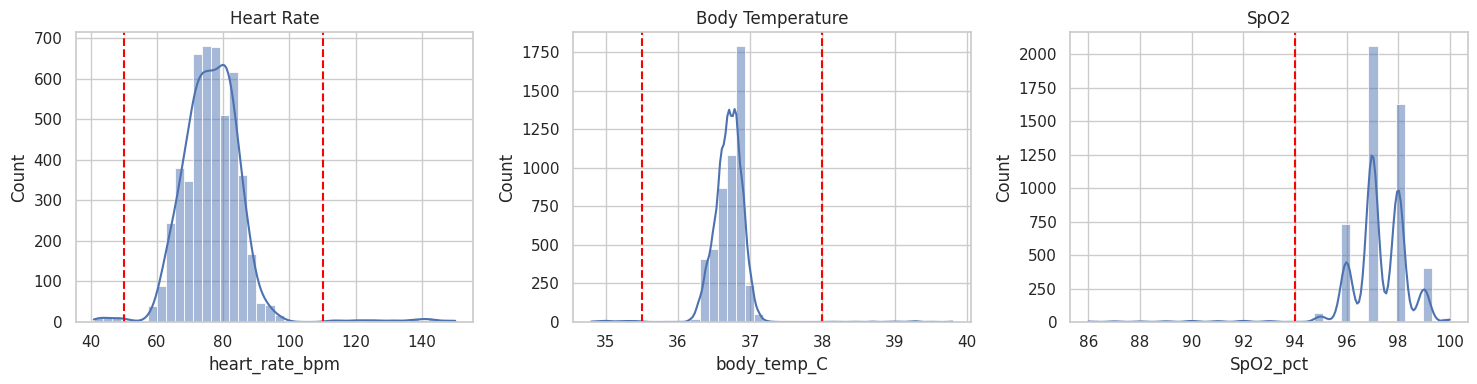

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["heart_rate_bpm"], bins=40, kde=True, ax=ax[0])
ax[0].axvline(50, color="red", linestyle="--")
ax[0].axvline(110, color="red", linestyle="--")
ax[0].set_title("Heart Rate")

sns.histplot(df["body_temp_C"], bins=40, kde=True, ax=ax[1])
ax[1].axvline(35.5, color="red", linestyle="--")
ax[1].axvline(38.0, color="red", linestyle="--")
ax[1].set_title("Body Temperature")

sns.histplot(df["SpO2_pct"], bins=40, kde=True, ax=ax[2])
ax[2].axvline(94, color="red", linestyle="--")
ax[2].set_title("SpO2")

plt.tight_layout()
plt.show()

### 4.2 Alert vs normal readings
Boxplots show how cleanly the alert class separates from normal readings on each vital.

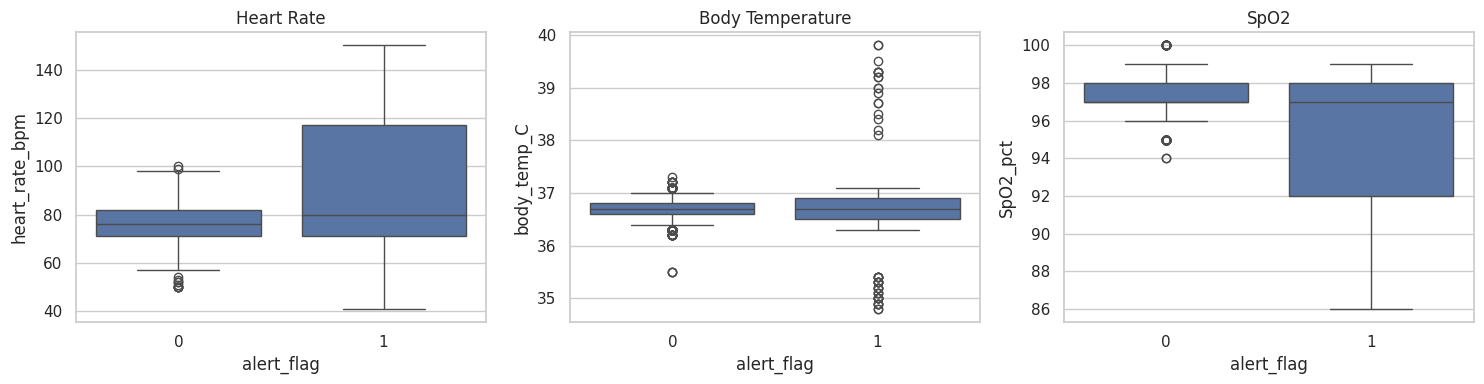

In [11]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.boxplot(x="alert_flag", y="heart_rate_bpm", data=df)
plt.title("Heart Rate")

plt.subplot(1, 3, 2)
sns.boxplot(x="alert_flag", y="body_temp_C", data=df)
plt.title("Body Temperature")

plt.subplot(1, 3, 3)
sns.boxplot(x="alert_flag", y="SpO2_pct", data=df)
plt.title("SpO2")

plt.tight_layout()
plt.show()

### 4.3 Heart rate vs SpO2
Alerts occupy the extremes: high or low heart rate, and SpO2 dropping below the normal band.

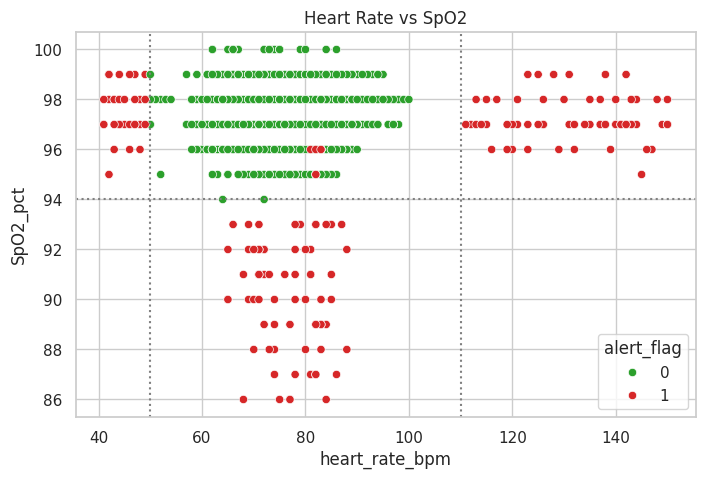

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="heart_rate_bpm", y="SpO2_pct",
                hue="alert_flag", palette=["#2ca02c", "#d62728"])

plt.axvline(50, color="grey", linestyle=":")
plt.axvline(110, color="grey", linestyle=":")
plt.axhline(94, color="grey", linestyle=":")

plt.title("Heart Rate vs SpO2")
plt.show()

### 4.4 One patient over time
A single patient's vitals drift slowly around their own baseline. Anomalies appear as short bursts, so alerting on one noisy reading would cause false alarms; a short confirmation window is sensible.

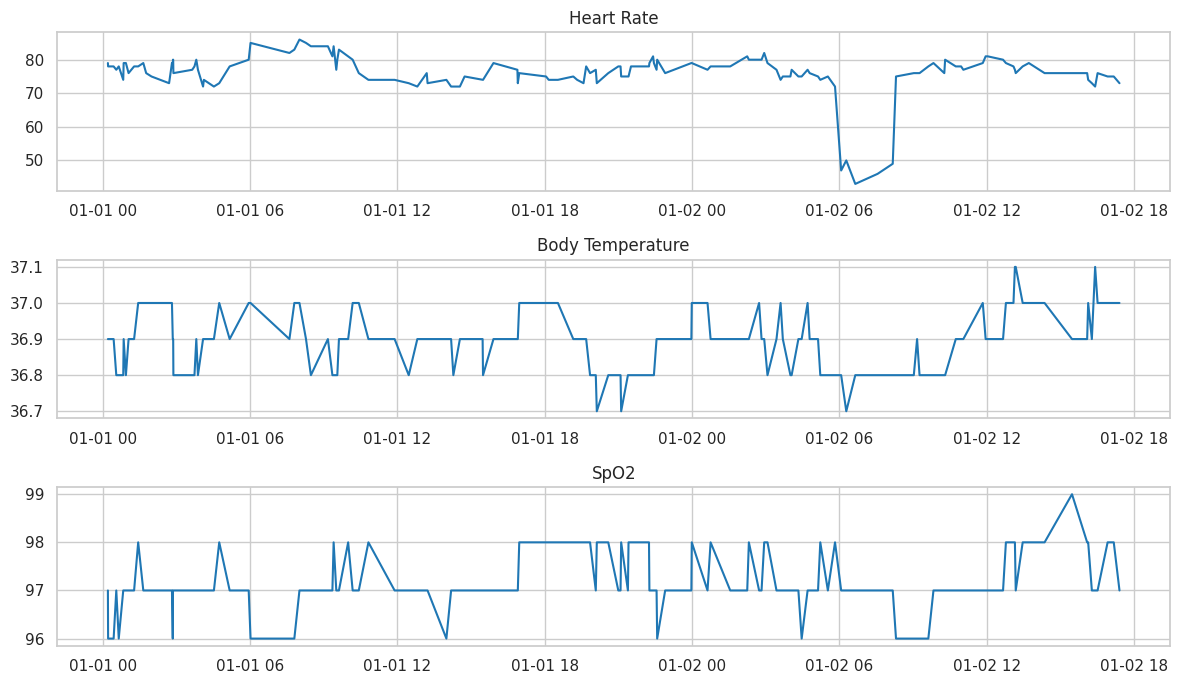

In [13]:
pid = df["patient_id"].value_counts().index[0]
p = df[df["patient_id"] == pid]

plt.figure(figsize=(12, 7))

plt.subplot(3, 1, 1)
plt.plot(p["timestamp"], p["heart_rate_bpm"], color="#1f77b4")
plt.title("Heart Rate")

plt.subplot(3, 1, 2)
plt.plot(p["timestamp"], p["body_temp_C"], color="#1f77b4")
plt.title("Body Temperature")

plt.subplot(3, 1, 3)
plt.plot(p["timestamp"], p["SpO2_pct"], color="#1f77b4")
plt.title("SpO2")

plt.tight_layout()
plt.show()

### 4.5 Alert rate by communication channel and correlation

/tmp/ipykernel_48/1242756419.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate = df.groupby("comm_channel")["alert_flag"].mean() * 100


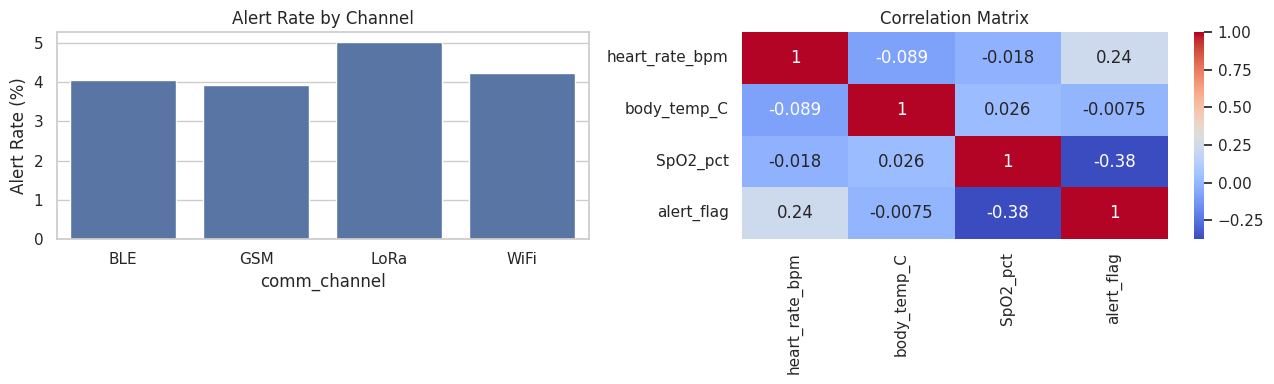

In [14]:
plt.figure(figsize=(13, 4))

plt.subplot(1, 2, 1)
rate = df.groupby("comm_channel")["alert_flag"].mean() * 100
sns.barplot(x=rate.index, y=rate.values)
plt.title("Alert Rate by Channel")
plt.ylabel("Alert Rate (%)")

plt.subplot(1, 2, 2)
sns.heatmap(df[["heart_rate_bpm", "body_temp_C", "SpO2_pct", "alert_flag"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

Validating the Firmware Alert Rule
The ESP32 uses simple threshold values to detect abnormal readings and generate alerts. We compare these alerts with the existing alert_flag values to check whether the rule works correctly.

The alert labels were created using the same thresholds. Therefore, 100% agreement is expected. This only confirms that the firmware logic is consistent with the dataset; it does not prove medical accuracy. For real-world use, the system should be tested against events labelled by healthcare professionals. We also test individual vital signs to understand why monitoring all three sensors is important.

In [15]:
from sklearn.metrics import confusion_matrix, classification_report

rule = (
    (df["heart_rate_bpm"] < 50) |
    (df["heart_rate_bpm"] > 110) |
    (df["SpO2_pct"] < 94) |
    (df["body_temp_C"] > 38) |
    (df["body_temp_C"] < 35.5)
).astype(int)

print("Agreement:", (rule == df["alert_flag"]).mean() * 100, "%")

print("Confusion Matrix:")
print(confusion_matrix(df["alert_flag"], rule))

hr_only = (
    (df["heart_rate_bpm"] < 50) |
    (df["heart_rate_bpm"] > 110)
).astype(int)

print("Heart Rate Only:")
print(classification_report(df["alert_flag"], hr_only))

Agreement: 100.0 %
Confusion Matrix:
[[4787    0]
 [   0  213]]
Heart Rate Only:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      4787
           1       1.00      0.45      0.62       213

    accuracy                           0.98      5000
   macro avg       0.99      0.72      0.80      5000
weighted avg       0.98      0.98      0.97      5000



Key Findings
1. Data Quality: The dataset was clean, with no missing values, duplicate records, or invalid readings. All timestamps were in the correct order.

2. Alert Distribution: Only around 4% of the readings were marked as alerts. Therefore, accuracy alone is not enough to evaluate the system. Precision and recall are also important.

3. Normal Readings: The average heart rate was around 77 bpm, body temperature was 36.7 °C, and SpO2 was approximately 97%.

4. Alert Patterns: Abnormal readings sometimes occurred repeatedly for the same patient. Using two consecutive abnormal readings before generating an alert may help reduce unnecessary notifications.

5. Importance of All Sensors: Using only heart rate detected approximately 45% of the alerts (recall = 0.446). This means some abnormal readings related to temperature and SpO2 were missed. Therefore, all three sensors are important.

6. Communication Channels: The alert rate remained around 4–5% across Wi-Fi, BLE, LoRa, and GSM. This suggests that the communication channel does not significantly affect the occurrence of alerts.

7. Limitations: The dataset is synthetic, and alert labels were generated using predefined rules. Therefore, these results should not be treated as proof of real-world performance. Further testing with actual device readings is required.

In [16]:
data = {
    "Column": [
        "timestamp",
        "patient_id",
        "heart_rate_bpm",
        "body_temp_C",
        "SpO2_pct",
        "comm_channel",
        "alert_flag"
    ],
    "Description": [
        "Date and time of health reading",
        "Unique patient identification",
        "Heart rate in beats per minute",
        "Body temperature in Celsius",
        "Blood oxygen saturation percentage",
        "Communication channel used",
        "Alert status (0 = Normal, 1 = Alert)"
    ]
}

dictionary = pd.DataFrame(data)
dictionary.to_csv("data_dictionary.csv", index=False)

print(dictionary)

           Column                           Description
0       timestamp       Date and time of health reading
1      patient_id         Unique patient identification
2  heart_rate_bpm        Heart rate in beats per minute
3     body_temp_C           Body temperature in Celsius
4        SpO2_pct    Blood oxygen saturation percentage
5    comm_channel            Communication channel used
6      alert_flag  Alert status (0 = Normal, 1 = Alert)


In [18]:
def check_alert(heart_rate, temperature, spo2):

    if (heart_rate < 50 or heart_rate > 110 or
        temperature < 35.5 or temperature > 38 or
        spo2 < 94):
        return 1

    return 0

In [19]:
print(check_alert(75, 36.7, 97))
print(check_alert(120, 36.7, 97))
print(check_alert(75, 36.7, 90))

0
1
1


In [20]:
import random

data = []

for i in range(20):
    heart_rate = random.randint(60, 120)
    temperature = round(random.uniform(35, 39), 1)
    spo2 = random.randint(90, 100)

    alert = check_alert(heart_rate, temperature, spo2)

    data.append([heart_rate, temperature, spo2, alert])

simulated_df = pd.DataFrame(data, columns=[
    "heart_rate_bpm", "body_temp_C", "SpO2_pct", "alert_flag"
])

print(simulated_df)

    heart_rate_bpm  body_temp_C  SpO2_pct  alert_flag
0               96         35.7        98           0
1               85         37.0       100           0
2               91         36.1        95           0
3              107         35.4        97           1
4               70         37.0        92           1
5               70         38.9        94           1
6               66         38.0        93           1
7               70         35.7        96           0
8              116         37.1        97           1
9              100         37.1        97           0
10             100         37.3        97           0
11              84         35.2        99           1
12              80         38.8        99           1
13              86         35.7        94           0
14              79         37.9        94           0
15              90         35.3        96           1
16             103         35.6        90           1
17              77         3

In [21]:
simulated_df["timestamp"] = pd.date_range(
    start="2026-10-30", periods=20, freq="min"
)

simulated_df["patient_id"] = "P001"
simulated_df["comm_channel"] = "WiFi"

simulated_df.to_csv("simulated_sensor_data.csv", index=False)

print("Sensor data saved successfully")
print(simulated_df.head())

Sensor data saved successfully
   heart_rate_bpm  body_temp_C  SpO2_pct  alert_flag           timestamp patient_id comm_channel
0              96         35.7        98           0 2026-10-30 00:00:00       P001         WiFi
1              85         37.0       100           0 2026-10-30 00:01:00       P001         WiFi
2              91         36.1        95           0 2026-10-30 00:02:00       P001         WiFi
3             107         35.4        97           1 2026-10-30 00:03:00       P001         WiFi
4              70         37.0        92           1 2026-10-30 00:04:00       P001         WiFi


In [24]:
import json

for _, row in simulated_df.iterrows():
    message = row.to_dict()
    message["timestamp"] = str(message["timestamp"])

    payload = json.dumps(message)

    print("Topic: patient/monitor/data")
    print("Message:", payload)
    print()

Topic: patient/monitor/data
Message: {"heart_rate_bpm": 96, "body_temp_C": 35.7, "SpO2_pct": 98, "alert_flag": 0, "timestamp": "2026-10-30 00:00:00", "patient_id": "P001", "comm_channel": "WiFi"}

Topic: patient/monitor/data
Message: {"heart_rate_bpm": 85, "body_temp_C": 37.0, "SpO2_pct": 100, "alert_flag": 0, "timestamp": "2026-10-30 00:01:00", "patient_id": "P001", "comm_channel": "WiFi"}

Topic: patient/monitor/data
Message: {"heart_rate_bpm": 91, "body_temp_C": 36.1, "SpO2_pct": 95, "alert_flag": 0, "timestamp": "2026-10-30 00:02:00", "patient_id": "P001", "comm_channel": "WiFi"}

Topic: patient/monitor/data
Message: {"heart_rate_bpm": 107, "body_temp_C": 35.4, "SpO2_pct": 97, "alert_flag": 1, "timestamp": "2026-10-30 00:03:00", "patient_id": "P001", "comm_channel": "WiFi"}

Topic: patient/monitor/data
Message: {"heart_rate_bpm": 70, "body_temp_C": 37.0, "SpO2_pct": 92, "alert_flag": 1, "timestamp": "2026-10-30 00:04:00", "patient_id": "P001", "comm_channel": "WiFi"}

Topic: patien

In [26]:
import json

messages = []

for _, row in simulated_df.iterrows():
    messages.append(json.loads(row.to_json(date_format="iso")))

for msg in messages:
    if msg["alert_flag"] == 1:
        print("ALERT! Patient:", msg["patient_id"])
        print("Heart Rate:", msg["heart_rate_bpm"])
        print("Temperature:", msg["body_temp_C"])
        print("SpO2:", msg["SpO2_pct"])

ALERT! Patient: P001
Heart Rate: 107
Temperature: 35.4
SpO2: 97
ALERT! Patient: P001
Heart Rate: 70
Temperature: 37.0
SpO2: 92
ALERT! Patient: P001
Heart Rate: 70
Temperature: 38.9
SpO2: 94
ALERT! Patient: P001
Heart Rate: 66
Temperature: 38.0
SpO2: 93
ALERT! Patient: P001
Heart Rate: 116
Temperature: 37.1
SpO2: 97
ALERT! Patient: P001
Heart Rate: 84
Temperature: 35.2
SpO2: 99
ALERT! Patient: P001
Heart Rate: 80
Temperature: 38.8
SpO2: 99
ALERT! Patient: P001
Heart Rate: 90
Temperature: 35.3
SpO2: 96
ALERT! Patient: P001
Heart Rate: 103
Temperature: 35.6
SpO2: 90
ALERT! Patient: P001
Heart Rate: 77
Temperature: 37.0
SpO2: 92
ALERT! Patient: P001
Heart Rate: 113
Temperature: 36.2
SpO2: 98
ALERT! Patient: P001
Heart Rate: 66
Temperature: 38.1
SpO2: 98


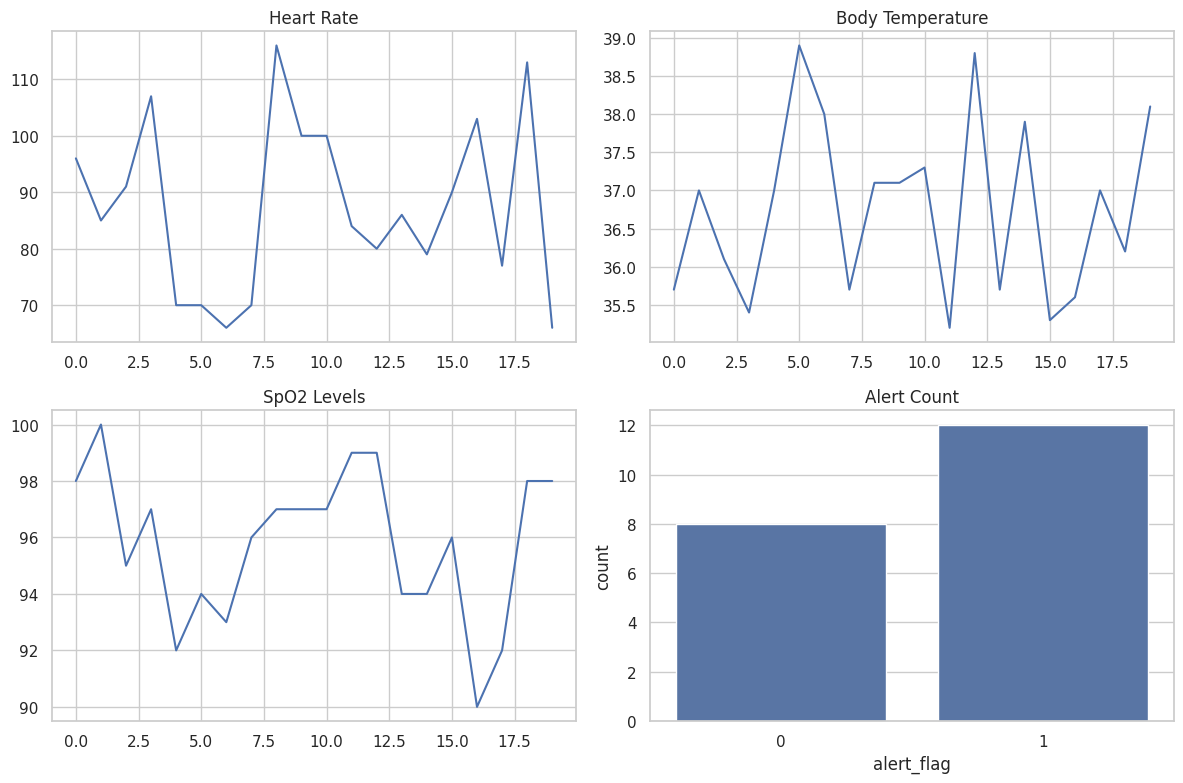

In [29]:

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].plot(simulated_df["heart_rate_bpm"])
ax[0, 0].set_title("Heart Rate")

ax[0, 1].plot(simulated_df["body_temp_C"])
ax[0, 1].set_title("Body Temperature")

ax[1, 0].plot(simulated_df["SpO2_pct"])
ax[1, 0].set_title("SpO2 Levels")

sns.countplot(data=simulated_df, x="alert_flag", ax=ax[1, 1])
ax[1, 1].set_title("Alert Count")

plt.tight_layout()
plt.show()

In [30]:
print("Total Readings:", len(simulated_df))
print("Normal Readings:", (simulated_df["alert_flag"] == 0).sum())
print("Alert Readings:", (simulated_df["alert_flag"] == 1).sum())

print("Missing Values:", simulated_df.isnull().sum().sum())

print("Alert Logic Check:",
      (simulated_df["alert_flag"] ==
       simulated_df.apply(
           lambda x: check_alert(
               x["heart_rate_bpm"],
               x["body_temp_C"],
               x["SpO2_pct"]
           ), axis=1
       )).all())

Total Readings: 20
Normal Readings: 8
Alert Readings: 12
Missing Values: 0
Alert Logic Check: True


In [31]:
results = pd.DataFrame({
    "Test Case": [
        "Total Readings",
        "Normal Readings",
        "Alert Readings",
        "Missing Values",
        "Alert Logic"
    ],
    "Result": [
        len(simulated_df),
        (simulated_df["alert_flag"] == 0).sum(),
        (simulated_df["alert_flag"] == 1).sum(),
        simulated_df.isnull().sum().sum(),
        "Passed"
    ]
})

results.to_csv("test_results.csv", index=False)

print(results)
print("\nTesting report saved successfully!")

         Test Case  Result
0   Total Readings      20
1  Normal Readings       8
2   Alert Readings      12
3   Missing Values       0
4      Alert Logic  Passed

Testing report saved successfully!


# Patient Health Monitoring System

## Project Overview
The Patient Health Monitoring System is an Embedded IoT-based project designed to monitor important health parameters such as heart rate, body temperature and blood oxygen saturation (SpO2).

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- MQTT (proposed communication protocol)
- Kaggle Notebook

## Project Modules
1. Dataset cleaning and preprocessing
2. Exploratory Data Analysis
3. Threshold-based alert detection
4. Sensor data simulation
5. MQTT message-format simulation
6. Patient monitoring visualizations
7. Testing and validation

## Alert Conditions
- Heart rate below 50 or above 110 bpm
- Body temperature below 35.5°C or above 38°C
- SpO2 below 94%

## Execution
1. Install the required Python libraries.
2. Open the Jupyter Notebook.
3. Load the cleaned dataset.
4. Run all notebook cells sequentially.
5. Review the generated visualizations and test results.

## Project Limitations
Sensor readings and communication messages were simulated in the current implementation. Physical ESP32 integration and live MQTT broker communication have not yet been validated.

## Output Files
- dataset_clean.csv
- data_dictionary.csv
- simulated_sensor_data.csv
- test_results.csv

## Disclaimer
This project is an academic prototype and is not intended for medical diagnosis.